# ECE488 — DiffuserCam lensless reconstruction

Data: DiffuserCam Lensless Mirflickr (Monakhova et al., 2019), Hugging Face copy
`bezzam/DiffuserCam-Lensless-Mirflickr-Dataset-NORM` (normalized, downsampled ×2 vs. the original Drive release).
Everything downloads to the **Colab runtime's disk**, not your laptop.

## 1. Setup

In [1]:
!nvidia-smi -L || echo "No GPU: switch to a Colab GPU runtime for training"
!pip install -q datasets tifffile

import os
import numpy as np
import torch
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("cwd:", os.getcwd(), "| device:", device)

/bin/bash: line 1: nvidia-smi: command not found
No GPU: switch to a Colab GPU runtime for training
cwd: /content | device: cpu


## 2. Load the dataset

`N_TRAIN` / `N_TEST` limit how many pairs you work with. Start small while debugging, set to `None` for everything.
Note: slicing still downloads the full parquet shards (~7.6 GB) once; it just limits what you iterate over.

In [2]:
from datasets import load_dataset
from huggingface_hub import hf_hub_download

REPO = "bezzam/DiffuserCam-Lensless-Mirflickr-Dataset-NORM"
N_TRAIN = 1000   # None = all
N_TEST  = 200

def _split(name, n):
    return name if n is None else f"{name}[:{n}]"

train_hf = load_dataset(REPO, split=_split("train", N_TRAIN))
test_hf  = load_dataset(REPO, split=_split("test",  N_TEST))

print(train_hf)
print(train_hf.features)   # confirm column names: expected 'lensless' and 'lensed'

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/930 [00:00<?, ?B/s]

data/train-00000-of-00015.parquet: reconstructing file:   0%|          |  0.00B /  486MB            

data/train-00000-of-00015.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00015.parquet: reconstructing file:   0%|          |  0.00B /  484MB            

data/train-00001-of-00015.parquet: downloading bytes:           |  0.00B            

... (27 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/24000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/999 [00:00<?, ? examples/s]

Dataset({
    features: ['lensless', 'lensed'],
    num_rows: 1000
})
{'lensless': Image(mode=None, decode=True), 'lensed': Image(mode=None, decode=True)}


## 3. Load the PSF

In [3]:
import tifffile

psf_path = hf_hub_download(REPO, "psf.tiff", repo_type="dataset")
psf = tifffile.imread(psf_path).astype(np.float32)
print("PSF raw:", psf.shape, psf.dtype, psf.min(), psf.max())

psf.tiff: reconstructing file:   0%|          |  0.00B / 6.23MB            

psf.tiff: downloading bytes:           |  0.00B            

PSF raw: (1080, 1920, 3) float32 0.0 255.0


## 4. Convert to tensors

`to_float` turns whatever comes back (PIL image or array, 8- or 16-bit) into a float32 `H×W×C` array in [0, 1].
Then we check that the PSF and the lensless images have the same size, since the forward model `b = crop(h * x)` requires it.

In [4]:
def to_float(img):
    a = np.asarray(img)
    if np.issubdtype(a.dtype, np.integer):
        a = a.astype(np.float32) / np.iinfo(a.dtype).max
    else:
        a = a.astype(np.float32)
    if a.ndim == 2:
        a = a[..., None]
    return a

ex = train_hf[0]
lensless0, lensed0 = to_float(ex["lensless"]), to_float(ex["lensed"])
print("lensless:", lensless0.shape, "| lensed:", lensed0.shape)

# --- PSF preprocessing: match the lensless image size ---
psf_f = psf if psf.ndim == 3 else psf[..., None]
if psf_f.max() > 1:
    psf_f = psf_f / psf_f.max()
if psf_f.shape[:2] != lensless0.shape[:2]:
    import torch.nn.functional as F
    t = torch.from_numpy(psf_f).permute(2, 0, 1)[None]
    t = F.interpolate(t, size=lensless0.shape[:2], mode="area")
    psf_f = t[0].permute(1, 2, 0).numpy()
    print("PSF resized to", psf_f.shape)
# Subtract background and normalize energy (standard for convolutional models)
psf_f = np.clip(psf_f - np.median(psf_f), 0, None)
psf_f = psf_f / psf_f.sum(axis=(0, 1), keepdims=True)
print("PSF ready:", psf_f.shape)

lensless: (270, 480, 3) | lensed: (270, 480, 3)
PSF resized to (270, 480, 3)
PSF ready: (270, 480, 3)


## 5. Look at one example

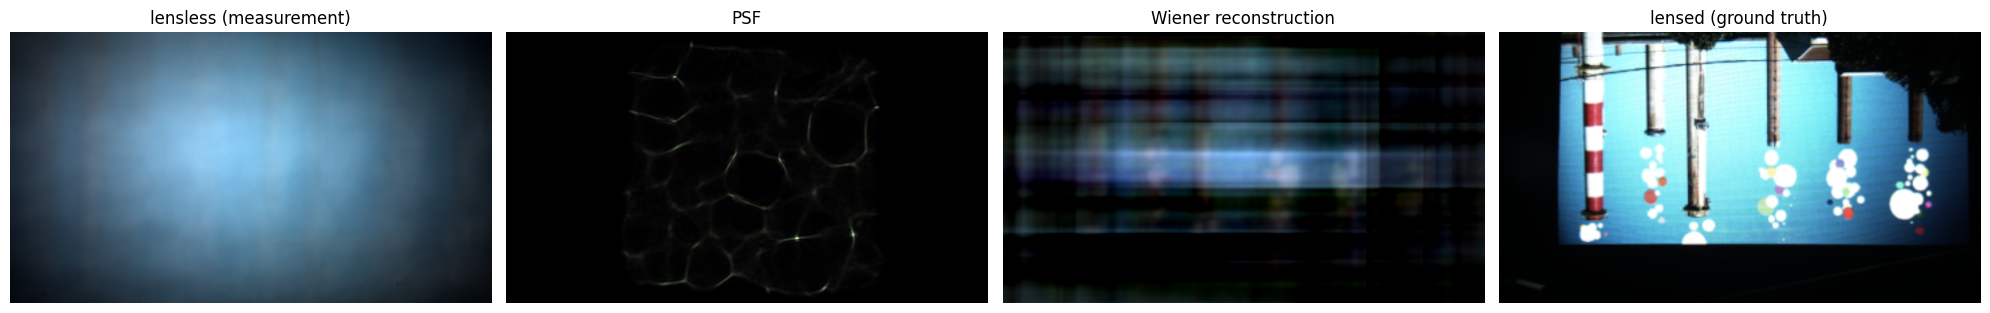

In [7]:
def show(a):
    a = np.clip(a, 0, None)
    a = a / max(a.max(), 1e-8)
    return a[..., 0] if a.shape[-1] == 1 else a

def wiener_deconv(b, h, lam=1e-3):
    """b: measurement H×W×C, h: PSF H×W×C (sums to 1 per channel). Returns H×W×C estimate."""
    H, W, C = b.shape
    ph, pw = H // 2, W // 2
    pad = lambda a: np.pad(a, ((ph, H - ph), (pw, W - pw), (0, 0)))   # 2H×2W, image centered
    Bf = np.fft.fft2(pad(b), axes=(0, 1))
    Hf = np.fft.fft2(np.fft.ifftshift(pad(h), axes=(0, 1)), axes=(0, 1))
    Xf = np.conj(Hf) * Bf / (np.abs(Hf) ** 2 + lam)
    x = np.real(np.fft.ifft2(Xf, axes=(0, 1)))
    return x[ph:ph + H, pw:pw + W]                                     # crop back to sensor size

recon0 = wiener_deconv(lensless0, psf_f, lam=1e-3)

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].imshow(show(lensless0)); ax[0].set_title("lensless (measurement)")
ax[1].imshow(show(psf_f));     ax[1].set_title("PSF")
ax[2].imshow(show(recon0));    ax[2].set_title("Wiener reconstruction")
ax[3].imshow(show(lensed0));   ax[3].set_title("lensed (ground truth)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

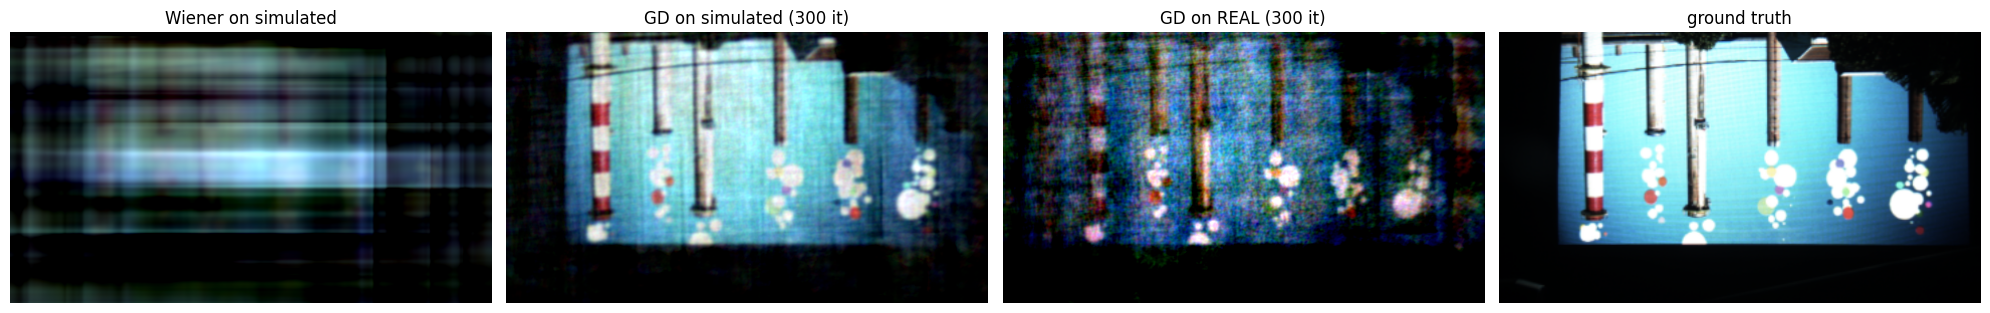

In [10]:
def make_ops(h_np):
    H, W, C = h_np.shape
    ph, pw = H // 2, W // 2
    hp = np.pad(h_np, ((ph, H - ph), (pw, W - pw), (0, 0)))
    hp = torch.from_numpy(hp).float().permute(2, 0, 1).to(device)
    Hf = torch.fft.rfft2(torch.fft.ifftshift(hp, dim=(-2, -1)))
    S = hp.shape[-2:]

    crop  = lambda v: v[..., ph:ph + H, pw:pw + W]
    def pad(v):
        out = torch.zeros(v.shape[0], *S, device=device)
        out[..., ph:ph + H, pw:pw + W] = v
        return out
    conv  = lambda v: torch.fft.irfft2(torch.fft.rfft2(v) * Hf, s=S)
    convT = lambda v: torch.fft.irfft2(torch.fft.rfft2(v) * Hf.conj(), s=S)

    A  = lambda x: crop(conv(x))      # forward:  scene (2H×2W) -> sensor (H×W)
    AT = lambda r: convT(pad(r))      # adjoint:  sensor -> scene
    return A, AT, crop

def gd_recon(b_np, h_np, iters=300, mu=1.0):
    """Nesterov-accelerated projected GD on 0.5||A x - b||^2, x >= 0.
    mu = 1 is safe: PSF sums to 1 and is nonnegative, so max|H(f)| = 1 and ||A||^2 <= 1."""
    A, AT, crop = make_ops(h_np)
    b = torch.from_numpy(b_np).float().permute(2, 0, 1).to(device)
    x = torch.zeros(b.shape[0], 2 * b.shape[1], 2 * b.shape[2], device=device)
    y, t = x.clone(), 1.0
    for _ in range(iters):
        x_new = torch.clamp(y - mu * AT(A(y) - b), min=0)
        t_new = (1 + (1 + 4 * t * t) ** 0.5) / 2
        y = x_new + ((t - 1) / t_new) * (x_new - x)
        x, t = x_new, t_new
    return crop(x).permute(1, 2, 0).cpu().numpy()

recon_sim  = gd_recon(b_sim.astype(np.float32), psf_f, iters=300)
recon_real = gd_recon(lensless0, psf_f, iters=300)

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].imshow(show(wiener_deconv(b_sim, psf_f, 1e-3))); ax[0].set_title("Wiener on simulated")
ax[1].imshow(show(recon_sim));                         ax[1].set_title("GD on simulated (300 it)")
ax[2].imshow(show(recon_real));                        ax[2].set_title("GD on REAL (300 it)")
ax[3].imshow(show(gt));                                ax[3].set_title("ground truth")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 6. PyTorch `Dataset` / `DataLoader`

Returns `(lensless, lensed)` as `C×H×W` float tensors, which is the layout PyTorch convolutions expect.

In [6]:
from torch.utils.data import Dataset, DataLoader

class DiffuserCamDataset(Dataset):
    def __init__(self, hf_ds):
        self.ds = hf_ds
    def __len__(self):
        return len(self.ds)
    def __getitem__(self, i):
        ex = self.ds[i]
        x = torch.from_numpy(to_float(ex["lensless"])).permute(2, 0, 1)
        y = torch.from_numpy(to_float(ex["lensed"])).permute(2, 0, 1)
        return x, y

train_ds, test_ds = DiffuserCamDataset(train_hf), DiffuserCamDataset(test_hf)
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True,  num_workers=2, pin_memory=(device == "cuda"))
test_loader  = DataLoader(test_ds,  batch_size=4, shuffle=False, num_workers=2)

psf_t = torch.from_numpy(psf_f).permute(2, 0, 1).to(device)   # C×H×W, used by ADMM

xb, yb = next(iter(train_loader))
print("batch:", xb.shape, yb.shape, "| psf:", psf_t.shape)

batch: torch.Size([4, 3, 270, 480]) torch.Size([4, 3, 270, 480]) | psf: torch.Size([3, 270, 480])
